In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, chi2
import pandas as pd

# Настройка стиля графиков
plt.style.use('ggplot')

# ==========================================
# 1. ПАРАМЕТРЫ ВАРИАНТА (N = 25)
# ==========================================
N = 25
T1 = N              # 25
T2 = N + 100        # 125
lambda1 = (N + 8) / (N + 24)   # 33/49 ≈ 0.67347
lambda2 = (N + 9) / (N + 25)   # 34/50 = 0.68
lambda_sum = lambda1 + lambda2 # ≈ 1.35347

K = 50              # Количество реализаций (потоков)
n_intervals = 25    # Количество интервалов
dt = (T2 - T1) / n_intervals # Длина интервала = 4

# Фиксируем seed для воспроизводимости результатов
rng = np.random.default_rng(42)

print(f"Вариант {N}: T1={T1}, T2={T2}")
print(f"Интенсивности: λ1={lambda1:.5f}, λ2={lambda2:.5f}, λ_сум={lambda_sum:.5f}")
print(f"Длина интервала Δt = {dt}")

Вариант 25: T1=25, T2=125
Интенсивности: λ1=0.67347, λ2=0.68000, λ_сум=1.35347
Длина интервала Δt = 4.0


константы. dt = 4 — это длина каждого «кармана» (интервала), на которые мы разобьем время от 25 до 125. Зачем нужен rng? Чтобы при повторном запуске программы числа были одинаковыми

Функция генерации потока и сбор данных

In [ ]:
# ==========================================
# 2. ГЕНЕРАЦИЯ ДАННЫХ
# ==========================================
def generate_poisson_flow(lam, T1, T2, rng):
    """Генерирует массив моментов времени наступления событий."""
    t = T1
    events = []
    while True:
        r = rng.random() # Кси (равномерное от 0 до 1)
        if r == 0: continue # Защита от log(0)
        u = -np.log(r) / lam # Метод обратной функции (Смирнов)
        t += u
        if t > T2:
            break
        events.append(t)
    return np.array(events)

def count_by_intervals(events, T1, T2, n_intervals):
    """Считает, сколько событий попало в каждый из n_intervals интервалов."""
    bins = np.linspace(T1, T2, n_intervals + 1)
    counts, _ = np.histogram(events, bins=bins)
    return counts

# Массивы для хранения 50 реализаций каждого потока
data_X1, data_X2, data_Xpr, data_Xtheor = [], [], [], []

for _ in range(K):
    flow1 = generate_poisson_flow(lambda1, T1, T2, rng)
    flow2 = generate_poisson_flow(lambda2, T1, T2, rng)

    # Практический суммарный поток (объединяем и сортируем!)
    flow_pr = np.sort(np.concatenate([flow1, flow2]))

    # Теоретический поток с суммарной интенсивностью
    flow_theor = generate_poisson_flow(lambda_sum, T1, T2, rng)

    # Записываем количество событий в 25 интервалах для каждой итерации
    data_X1.append(count_by_intervals(flow1, T1, T2, n_intervals))
    data_X2.append(count_by_intervals(flow2, T1, T2, n_intervals))
    data_Xpr.append(count_by_intervals(flow_pr, T1, T2, n_intervals))
    data_Xtheor.append(count_by_intervals(flow_theor, T1, T2, n_intervals))

# Превращаем в матрицы 50x25
X1 = np.array(data_X1)
X2 = np.array(data_X2)
Xpr = np.array(data_Xpr)
Xtheor = np.array(data_Xtheor)

print("Генерация завершена. Размер матрицы для X1:", X1.shape)

Генерация завершена. Размер матрицы для X1: (50, 25)


Статистика и расчет интенсивностей

In [ ]:
# ==========================================
# 3. СТАТИСТИЧЕСКАЯ ОБРАБОТКА
# ==========================================
def get_stats(matrix, dt):
    sample = matrix.ravel() # Разворачиваем 50x25 в плоский массив (1250 элементов)
    mean = sample.mean()             # Выборочное среднее M(eta)
    var = sample.var(ddof=0)         # Выборочная дисперсия D(eta)
    lambda_hat = mean / dt           # Оценка интенсивности
    return mean, var, lambda_hat

# Считаем для всех потоков
stats = {
    "X1": get_stats(X1, dt),
    "X2": get_stats(X2, dt),
    "Xпр": get_stats(Xpr, dt),
    "X(теор)": get_stats(Xtheor, dt)
}

# Выводим красивую табличку
df_stats = pd.DataFrame(stats, index=["Мат. ожидание (M)", "Дисперсия (D)", "Оценка λ"]).T
df_stats.loc["X1", "Теор. λ"] = lambda1
df_stats.loc["X2", "Теор. λ"] = lambda2
df_stats.loc["Xпр", "Теор. λ"] = lambda_sum
df_stats.loc["X(теор)", "Теор. λ"] = lambda_sum

print(df_stats.round(4))

         Мат. ожидание (M)  Дисперсия (D)  Оценка λ  Теор. λ
X1                   2.720         2.7408     0.680   0.6735
X2                   2.704         2.6596     0.676   0.6800
Xпр                  5.424         5.4970     1.356   1.3535
X(теор)              5.344         5.6641     1.336   1.3535


Критерий Пирсона (Хи квадрат)

In [ ]:
# ==========================================
# 4. КРИТЕРИЙ ПИРСОНА (ХИ-КВАДРАТ)
# ==========================================
def check_pearson_hypothesis(matrix, dt, alpha=0.05):
    sample = matrix.ravel()
    N_obs = len(sample) # 1250 наблюдений
    mu = sample.mean()  # Оценка параметра Пуассона для интервала (лямбда * дельта t)

    # Находим максимальное количество событий в одном интервале
    max_obs = int(sample.max())

    # 1. Эмпирические частоты (наблюдаемые)
    observed = np.bincount(sample.astype(int), minlength=max_obs + 1).astype(float)

    # 2. Теоретические частоты по формуле Пуассона
    expected = poisson.pmf(np.arange(max_obs + 1), mu) * N_obs

    # Добавляем "хвост" (все что больше max_obs) в последний карман
    tail_expected = (1 - poisson.cdf(max_obs, mu)) * N_obs
    expected[-1] += tail_expected

    # 3. Объединение редких карманов (где теор. частота < 5)
    # Это ОБЯЗАТЕЛЬНОЕ условие применения критерия Пирсона!
    groups = []
    i = 0
    while i < len(observed):
        obs_sum = observed[i]
        exp_sum = expected[i]
        start = i
        end = i
        # Пока теор частота меньше 5, приклеиваем следующий карман
        while exp_sum < 5 and end + 1 < len(observed):
            end += 1
            obs_sum += observed[end]
            exp_sum += expected[end]
        groups.append([start, end, obs_sum, exp_sum])
        i = end + 1

    # Если последняя группа получилась меньше 5, приклеиваем ее к предыдущей
    if len(groups) >= 2 and groups[-1][3] < 5:
        last = groups.pop()
        groups[-1][1] = last[1]
        groups[-1][2] += last[2]
        groups[-1][3] += last[3]

    # 4. Считаем хи-квадрат практический
    chi_square_stat = sum((obs - exp)**2 / exp for _, _, obs, exp in groups)

    # 5. Степени свободы: df = k - 1 - r, где r=1 (оценивали лямбду)
    df = len(groups) - 1 - 1

    # 6. Критическое значение из таблицы (через scipy)
    chi_square_critical = chi2.ppf(1 - alpha, df) if df > 0 else np.nan

    return chi_square_stat, chi_square_critical, df, len(groups)

# Проверяем гипотезу для практического суммарного потока
chi2_pract, chi2_crit, df_val, k_groups = check_pearson_hypothesis(Xpr, dt)

print(f"--- Проверка гипотезы для Xпр ---")
print(f"Количество карманов после объединения (k): {k_groups}")
print(f"Степени свободы (df): {df_val}")
print(f"Хи-квадрат практический: {chi2_pract:.4f}")
print(f"Хи-квадрат критический:  {chi2_crit:.4f}")
if chi2_pract < chi2_crit:
    print("ВЫВОД: χ²_практ < χ²_крит. Гипотеза о пуассоновском распределении НЕ ОТВЕРГАЕТСЯ.")
else:
    print("ВЫВОД: Гипотеза отвергается (поток не пуассоновский).")

--- Проверка гипотезы для Xпр ---
Количество карманов после объединения (k): 13
Степени свободы (df): 11
Хи-квадрат практический: 11.8635
Хи-квадрат критический:  19.6751
ВЫВОД: χ²_практ < χ²_крит. Гипотеза о пуассоновском распределении НЕ ОТВЕРГАЕТСЯ.


Визуализация

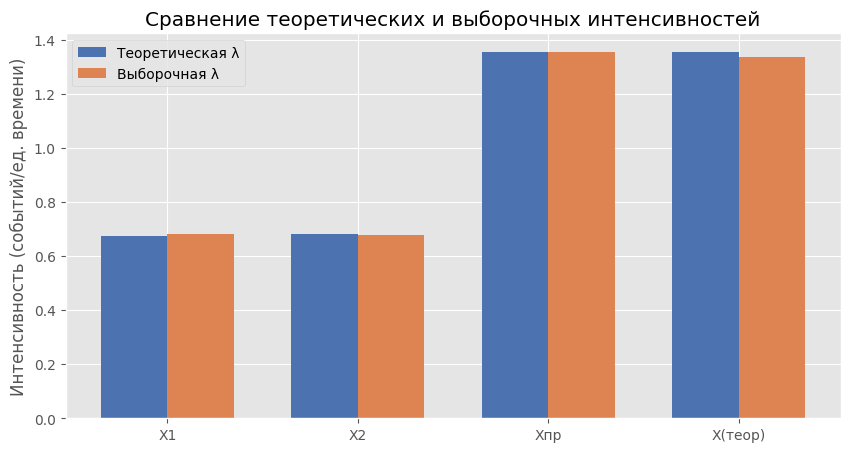

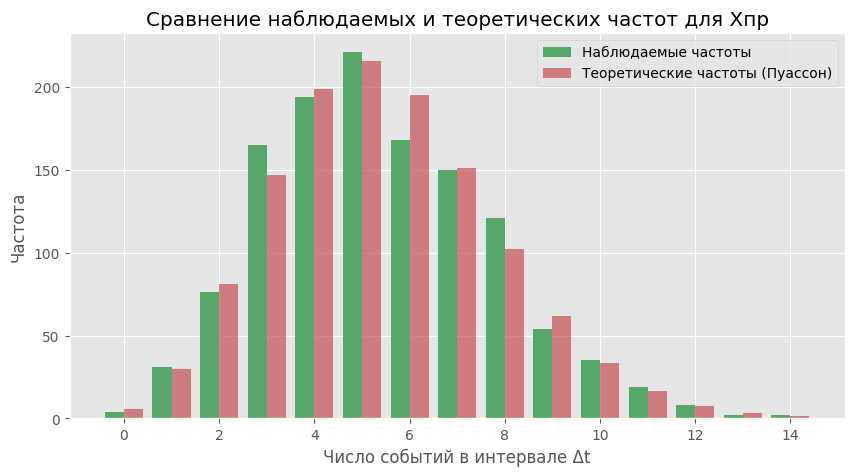

In [ ]:
# ==========================================
# 5. ГРАФИКИ
# ==========================================
# График 1: Сравнение интенсивностей
labels = ['X1', 'X2', 'Xпр', 'X(теор)']
theor_vals = [lambda1, lambda2, lambda_sum, lambda_sum]
sample_vals = [stats['X1'][2], stats['X2'][2], stats['Xпр'][2], stats['X(теор)'][2]]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, theor_vals, width, label='Теоретическая λ', color='#4c72b0')
rects2 = ax.bar(x + width/2, sample_vals, width, label='Выборочная λ', color='#dd8452')

ax.set_ylabel('Интенсивность (событий/ед. времени)')
ax.set_title('Сравнение теоретических и выборочных интенсивностей')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.show()

# График 2: Гистограмма частот для Xпр
sample = Xpr.ravel()
mu = sample.mean()
max_obs = int(sample.max())
observed = np.bincount(sample.astype(int), minlength=max_obs + 1)
expected = poisson.pmf(np.arange(max_obs + 1), mu) * len(sample)

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.4
x_vals = np.arange(len(observed))

ax.bar(x_vals - width/2, observed, width, label='Наблюдаемые частоты', color='#55a868')
ax.bar(x_vals + width/2, expected, width, label='Теоретические частоты (Пуассон)', color='#c44e52', alpha=0.7)

ax.set_xlabel('Число событий в интервале Δt')
ax.set_ylabel('Частота')
ax.set_title('Сравнение наблюдаемых и теоретических частот для Xпр')
ax.legend()
plt.show()